What we know from presvious modules:

My Dataset is called: Switzerland Greenhouse Gas Dataset.

It contains measurements for various greenhouse gases (air pollutants) like O3 (ozon), SO2 (sulfur dioxide) and NOX (nitrogen oxides = No2 & NO together) collected in 2023 for the whole of Switzerland, as well as the geodata variables longitude	and latitude.

And also contains the measured concentration for particulate matter (Feinstaub) where PM10 means Particulate Matter ≤ 10 μm (e.g. pollen, dust) and PM2.5 means Particulate Matter ≤ 2.5 μm (somke, soot).

Unit of measurement is for all the pollutants the same: µg/m³

The Dataset is huge consisting of only 7 columns but 1'048'576 rows (one is the header).

Source: Data records for individual pollutants were obtained from
Federal Office for the Environment (FOEN). (Bundesamt für Umwelt BAFU: Treibhausgasemissionen der Schweiz.)

Disclaimer: This excel is actually not downloadable on the BAFU website.

In [1]:
# Upload the local data file to colab
from google.colab import files
uploaded = files.upload()

Saving Switzerland Greenhouse Gas Dataset.xlsx to Switzerland Greenhouse Gas Dataset.xlsx


In [2]:
import numpy as np #this is where all the lin.alg. stuff is
import pandas as pd #needed to load my dataset
import matplotlib.pyplot as plt #needed to plot
import seaborn as sns #another plotting package

We don't have missing data so we have nothing to remove. And also don't have NA/NaN values to fill.
As I know the data is complete with no issues, I will now continue with the visualisation part.

To get a good visual intuition of the dataset we created histograms of the pollutant concentrations for each pollutant.
It helps to illustrate the following question:
Are most measurements low, or are there a few very high values?
And it helps understand distributions, skewness and possible outliers.



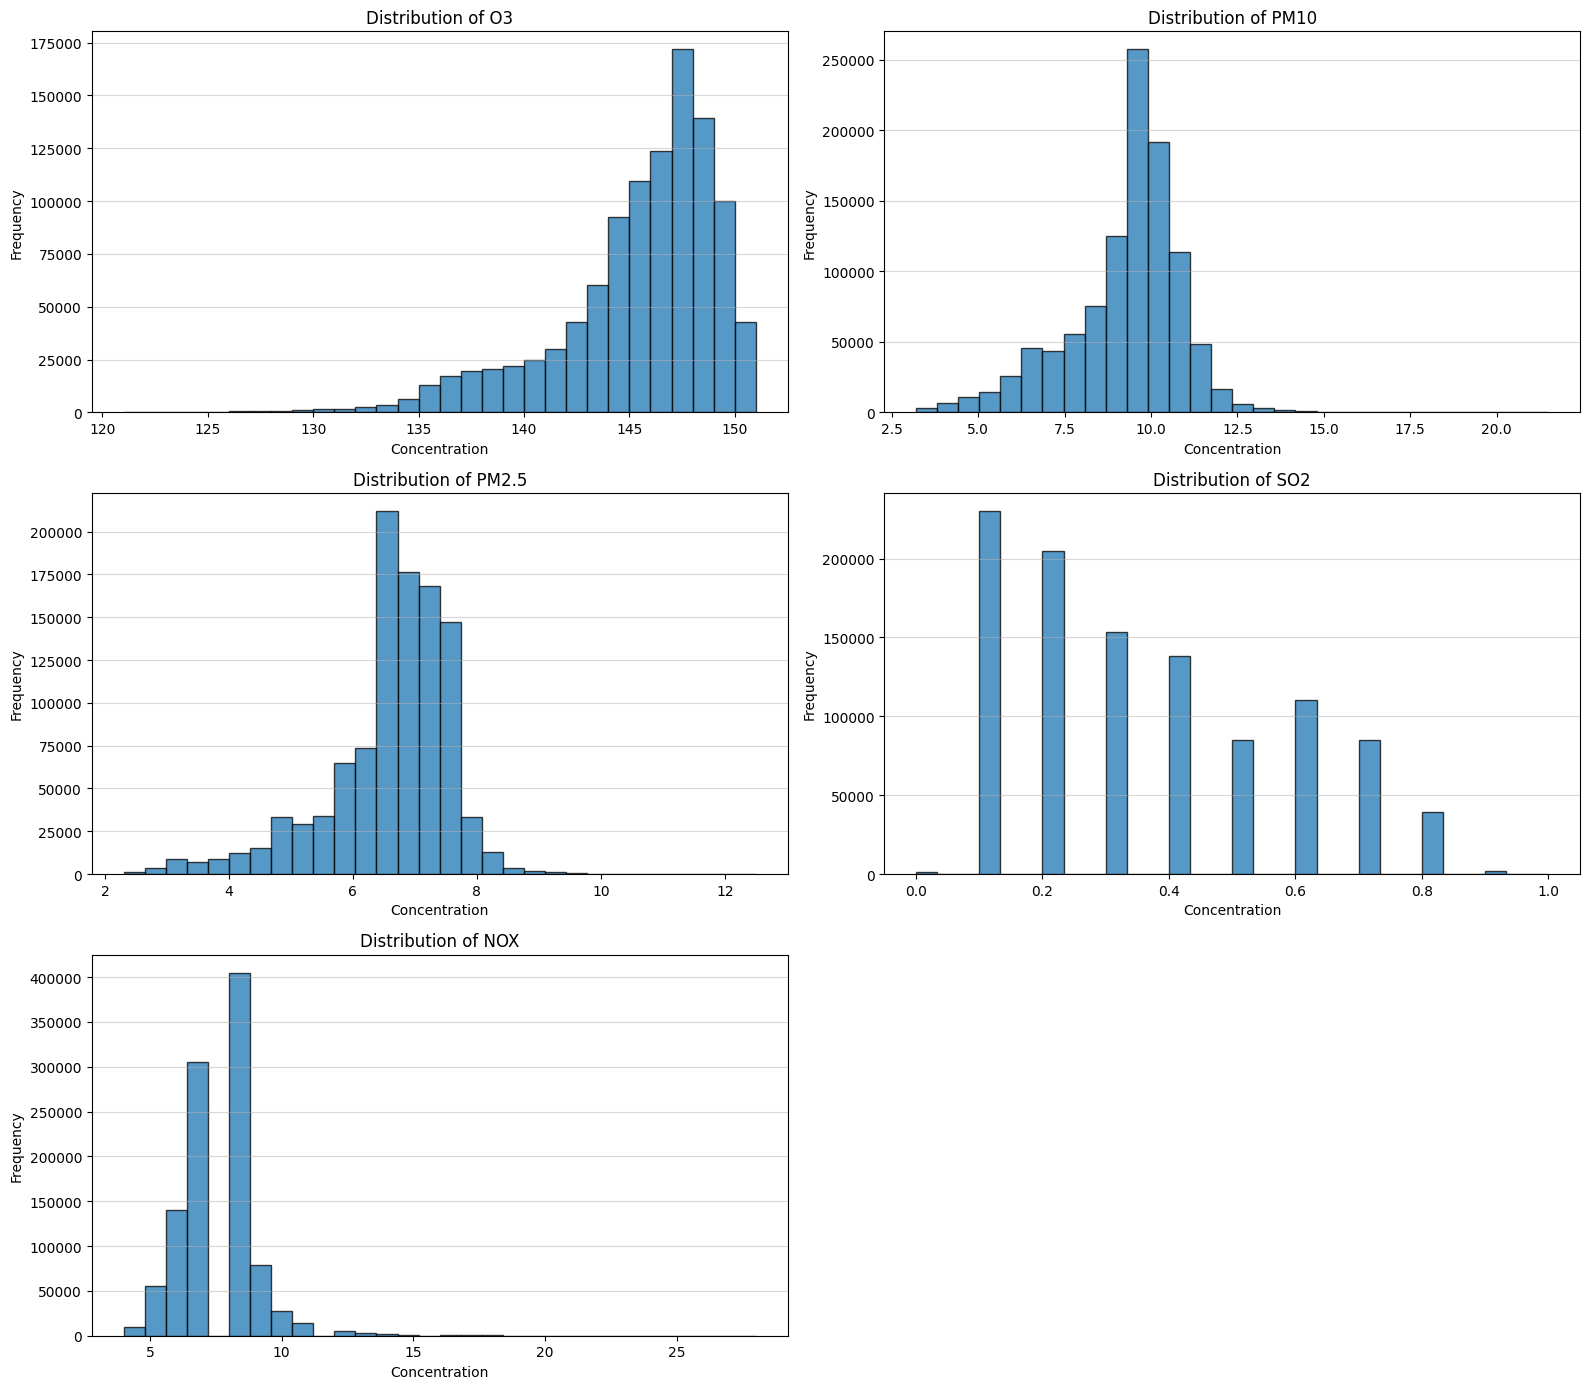

In [3]:
df = pd.read_excel("Switzerland Greenhouse Gas Dataset.xlsx")

# Define the pollutants and include pm
pollutants = ["O3", "PM10", "PM2.5", "SO2", "NOX"]

# Create a figure with 5 histograms

fig, axes = plt.subplots(3, 2, figsize=(16, 14))

#This line creates a figure containing 3 rows and 2 columns of subplots.
#So in total 6 separate plotting areas. The rest is just size.

axes = axes.flatten()

#this converts the two-dimensional arrangement of axes
#into a one-dimensional array, we need this for using enumerate more easily
#it could be done without flaten and instead of 3x2 I could use a 5 list, but
#3x2 gives us bigger plots.

#Plot each pollutant in its corresponding subplot

for i, pollutant in enumerate(pollutants):
    values = df[pollutant]

# Plot histogram
    axes[i].hist(values, bins=30, edgecolor="black", alpha=0.75)

    # Add labels and title
    axes[i].set_title(f"Distribution of {pollutant}")
    axes[i].set_xlabel("Concentration")
    axes[i].set_ylabel("Frequency")
    axes[i].grid(axis="y", alpha=0.5)

# Hide any unused subplots (we have 5 pollutants but 6 subplots)
#It would work without but looks neater that way.
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

Now we calculate some statistics. This makes it easier to identify which pollutants have the greatest spread and highest extreme values.

In [4]:
stats = df[pollutants].describe().T

stats["variance"] = df[pollutants].var()
stats["range"] = stats["max"] - stats["min"]
stats["IQR"] = stats["75%"] - stats["25%"] #Interquartile Range = IQR (Spread of the central 50%)
stats["skewness"] = df[pollutants].skew() #skewness = Whether a distribution has a longer tail on one side
stats["kurtosis"] = df[pollutants].kurtosis() #tells us if the distribution looks like a bell curve

display(stats.round(3))

,count,mean,std,min,25%,50%,75%,max,variance,range,IQR,skewness,kurtosis
O3,1048575.0,144.944,3.897,121.0,143.0,146.0,148.0,151.0,15.190,30.0,5.0,-1.373,2.144
PM10,1048575.0,9.272,1.645,3.2,8.5,9.6,10.3,21.5,2.706,18.3,1.8,-0.732,1.123
PM2.5,1048575.0,6.593,0.993,2.3,6.2,6.8,7.2,12.5,0.986,10.2,1.0,-1.255,2.249
SO2,1048575.0,0.349,0.213,0.0,0.2,0.3,0.5,1.0,0.045,1.0,0.3,0.524,-0.883
NOX,1048575.0,7.485,1.398,4.0,7.0,8.0,8.0,28.0,1.953,24.0,1.0,1.579,11.241


Keep in mind: For skewness, a positive value generally indicates a longer right tail (skew > 0 means leftskewed), while a negative value indicates a longer left tail (skew < 0 means rightskewed). Values near zero indicate approximate symmetry. Those calculations confirm our skewness findings in the histogramms above.

For kurtosis k < 0 means the peak is narrow and for k > 0 the peak is broad.

Keeping in mind that these are potential statistical outliers, not necessarily errors. They may represent local pollution peaks, unusual conditions, or data-quality issues.

To have a nice overwiev of our outliers and IQR and the median all in one table, we can do the follwoing.

In [5]:
import pandas as pd

pollutants = ["O3", "PM10", "PM2.5", "SO2", "NOX"]

results = []
n = len(df)

for pollutant in pollutants:
    q1 = df[pollutant].quantile(0.25)
    median = df[pollutant].median()
    q3 = df[pollutant].quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    below = df[pollutant] < lower_limit
    above = df[pollutant] > upper_limit
    total_outliers = int((below | above).sum())

    results.append({
        "Pollutant": pollutant,
        "Q1": q1,
        "Median": median,
        "Q3": q3,
        "IQR": iqr,
        "Lower limit": lower_limit,
        "Upper limit": upper_limit,
        "Low outliers": int(below.sum()),
        "High outliers": int(above.sum()),
        "Total outliers": total_outliers,
        "Highest observation": df[pollutant].max(),
        "Outliers (%)": 100 * total_outliers / n
    })

outlier_summary = pd.DataFrame(results).set_index("Pollutant")

display(outlier_summary.round(3))

,Q1,Median,Q3,IQR,Lower limit,Upper limit,Low outliers,High outliers,Total outliers,Highest observation,Outliers (%)
Pollutant,,,,,,,,,,,
O3,143.0,146.0,148.0,5.0,135.50,155.50,32675,0,32675,151.0,3.116
PM10,8.5,9.6,10.3,1.8,5.80,13.00,39353,6444,45797,21.5,4.368
PM2.5,6.2,6.8,7.2,1.0,4.70,8.70,56578,3819,60397,12.5,5.760
SO2,0.2,0.3,0.5,0.3,-0.25,0.95,0,38,38,1.0,0.004
NOX,7.0,8.0,8.0,1.0,5.50,9.50,64950,54570,119520,28.0,11.398


This adds an important perspective: what proportion of observations are classified as potential outliers?

A high proportion can occur because the distribution is strongly skewed, has several clusters, or has a narrow IQR relative to its tails. It does not necessarily indicate poor data quality. And as we found out previously my data is very skewed.

Hence I will not automatically delete these observations.

# Let's calculate the pearson correlation matrix
It examines if there is linear correlation.relationship

In [6]:
correlations = df[pollutants].corr(method="pearson")

display(correlations.round(3))

,O3,PM10,PM2.5,SO2,NOX
O3,1.000,0.244,0.238,0.026,-0.176
PM10,0.244,1.000,0.977,-0.077,-0.079
PM2.5,0.238,0.977,1.000,0.002,-0.053
SO2,0.026,-0.077,0.002,1.000,0.119
NOX,-0.176,-0.079,-0.053,0.119,1.000


Pearson correlation ranges from −1 to +1:

- Near +1: a strong positive linear relationship.

- Near −1: a strong negative linear relationship.

- Near 0: little or no linear relationship.

Correlation does not establish causation, and a low Pearson correlation does not rule out a nonlinear relationship.

# Visualize the correlations

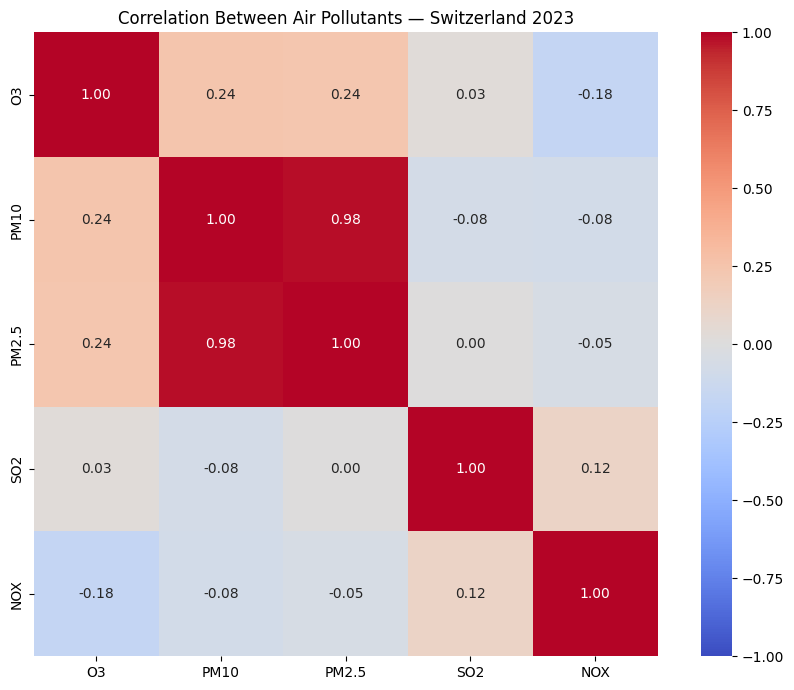

In [7]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Correlation Between Air Pollutants — Switzerland 2023")
plt.tight_layout()
plt.show()

# The most important finding: PM10 and PM2.5

A correlation of r=0.977 indicates that observations with higher PM10 concentrations tend to have higher PM2.5 concentrations, and vice versa. The relationship is exceptionally strong and positive. It only shows the strength of the observed linear relationships, this does not tell us whether the correlations are statistically distinguishable from zero.

The squared correlation is
r2=0.9772≈0.955.
In a simple linear regression with an intercept, this means that approximately 95.5% of the observed variation in one pollutant can be accounted for by its linear relationship with the other in this dataset. It does not mean that PM10 causes 95.5% of PM2.5, or that the pollutants have the same concentrations.

Now I know that there are other relationships that I might uncover that may not be linear with using another correlation measure.

And I also do not know if the correlations are driven by extreme observations. The results may change when using a rank-based measure such as Spearman correlation. Hence it can be useful to compare the two methods before automatically removing outliers.

Let's do this.

# Let's calculate the Spearman correlation matrix

My distributions contain many potential outliers. The Spearman correlation is based on ranks, so it can help determine whether associations persist when the exact numerical distances between observations matter less.

In [8]:
correlations = df[pollutants].corr(method="spearman")

display(correlations.round(3))

,O3,PM10,PM2.5,SO2,NOX
O3,1.000,0.238,0.221,0.016,-0.237
PM10,0.238,1.000,0.964,-0.036,-0.068
PM2.5,0.221,0.964,1.000,0.078,-0.012
SO2,0.016,-0.036,0.078,1.000,0.149
NOX,-0.237,-0.068,-0.012,0.149,1.000


Spearman's rank correlation coefficient \(r_s\), measures how consistently two variables move in the same or opposite direction, based on their ranks.

Unlike Pearson correlation, which measures linear relationships, Spearman correlation measures monotonic relationships: whether higher values of one variable generally correspond to higher or lower values of the other.

The coefficient ranges from \(-1\) to \(+1\):
- Close to +1: Higher values of one pollutant tend to accompany higher values of the other.
- Close to 0: Little or no monotonic association.
- Close to −1: Higher values of one pollutant tend to accompany lower values of the other.

# Visualize the correlations

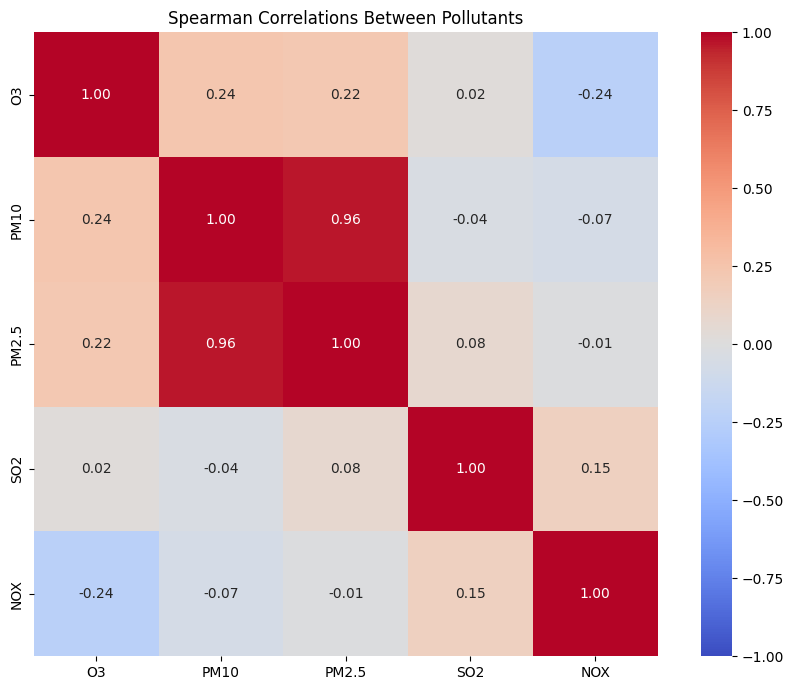

In [9]:
spearman_corr = df[pollutants].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Spearman Correlations Between Pollutants")
plt.tight_layout()
plt.show()

# The most important finding: PM10 and PM2.5

A correlation of r=0.964 indicates a very strong positive monotonic relationship: observations with higher PM10 concentrations generally also have higher PM2.5 concentrations.

The difference between the two coefficients is = 0.013, also very close. This suggests that the strong relationship is not merely an artefact of the exact concentration values or a few extreme observations. The pollutants also show a strong association when their values are converted into ranks.

However, the similarity of the coefficients does not prove that there are no outliers or that the relationship is perfectly linear. A scatterplot would help assess that.

# Is the PM10–PM2.5 association statistically distinguishable from zero?

This is the specific research question we want to answer. Let's formulate it as a hypothesis test:

    Null hypothesis (H0​): The population Pearson correlation between PM10 and PM2.5 is zero, ρ=0.

    Alternative hypothesis (H1​): The population Pearson correlation is not zero, ρ≠0.

I will use a significance level of alpha=0.05.

(This means that if the p-value is below 0.05, the null hypothesis is rejected in favor of a nonzero linear association, subject to the test's assumptions.)

Next step: obtain the correlation, p-value, confidence interval, and sample size.

# Pearson correlation test

In [10]:
from scipy.stats import pearsonr

# Select paired observations
data = df[["PM10", "PM2.5"]].dropna()

# Calculate Pearson correlation and p-value
r, p_value = pearsonr(data["PM10"], data["PM2.5"])

# Print results
print("PM10 and PM2.5: Pearson correlation test")
print("-----------------------------------------")
print(f"Number of observations: {len(data):,}")
print(f"Pearson correlation (r): {r:.6f}")
print(f"P-value: {p_value:.6e}")
print(f"Significance level: 0.05")

if p_value < 0.05:
    print("\nDecision: Reject the null hypothesis.")
    print("The association is statistically distinguishable from zero.")
else:
    print("\nDecision: Do not reject the null hypothesis.")
    print("There is insufficient evidence of a nonzero linear association.")

PM10 and PM2.5: Pearson correlation test
-----------------------------------------
Number of observations: 1,048,575
Pearson correlation (r): 0.977145
P-value: 0.000000e+00
Significance level: 0.05

Decision: Reject the null hypothesis.
The association is statistically distinguishable from zero.


**Pearson's \(r\):** measures the strength and direction of the linear association. A positive value means higher PM10 tends to occur alongside higher PM2.5; a negative value means they tend to vary in opposite directions.

**The p-value:** measures how incompatible the observed correlation is with the null hypothesis of zero population correlation, under the test's assumptions.

## Results of the Pearson correlation test

The results indicate that PM10 and PM2.5 are very strongly positively associated in the observed dataset. The test also reports overwhelming statistical evidence against a zero population Pearson correlation, assuming its inferential assumptions hold.

The correlation is not merely statistically significant; it is also very strong.

**Decision**: Reject the null hypothesis under the assumptions of the standard Pearson correlation test.

**Disclaimer**: The standard Pearson test assumes independent paired observations for its usual p-value calculation. Spatial dependence or repeated measurements can make the reported p-value overly optimistic

# Visual Analysis of the Association Between PM10 and PM2.5

With a large dataset, plotting every point can be slow and make the graph difficult to read. A hexbin plot shows where observations are concentrated.

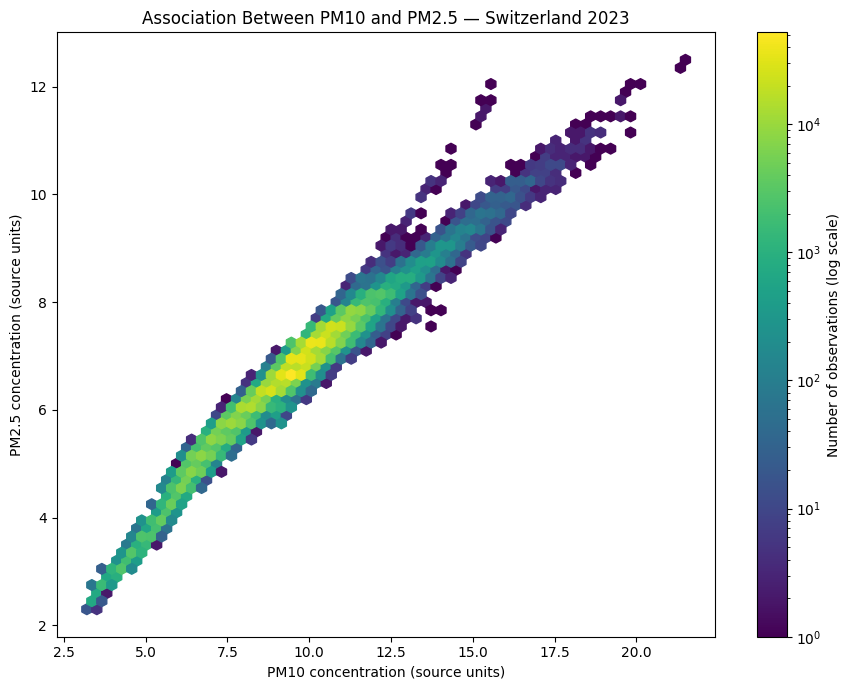

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))

plt.hexbin(
    data["PM10"],
    data["PM2.5"],
    gridsize=60,
    mincnt=1,
    bins="log"
)

plt.colorbar(label="Number of observations (log scale)")
plt.xlabel("PM10 concentration (source units)")
plt.ylabel("PM2.5 concentration (source units)")
plt.title("Association Between PM10 and PM2.5 — Switzerland 2023")

plt.tight_layout()
plt.show()

The hexbin plot shows a very strong positive association between PM10 and PM2.5 concentrations. The observations form a narrow, upward-sloping band, indicating that higher PM10 concentrations generally correspond to higher PM2.5 concentrations. The highest observation density occurs approximately around PM10 concentrations of 9–12 and PM2.5 concentrations of 6–8 source units.

This visual pattern is consistent with the Pearson correlation coefficient of 0.977145 and the Spearman rank correlation coefficient of 0.964. Although the association is very strong, the plotted relationship appears somewhat curved, suggesting that it may not be perfectly linear across the full concentration range. The plot therefore complements the correlation analysis but does not, by itself, establish statistical significance or causation.

**Next step:** Add a regression line to the plot and examine the residuals. This will help to distinguish a strong association from a relationship that is also well described by a linear model.
Let's fit a linear regression model:

# Linear Regression Model

Linear regression: PM2.5 predicted from PM10
Intercept: 1.1258
Slope:     0.5897
R-squared: 0.9548
RMSE:      0.2110
MAE:       0.1700


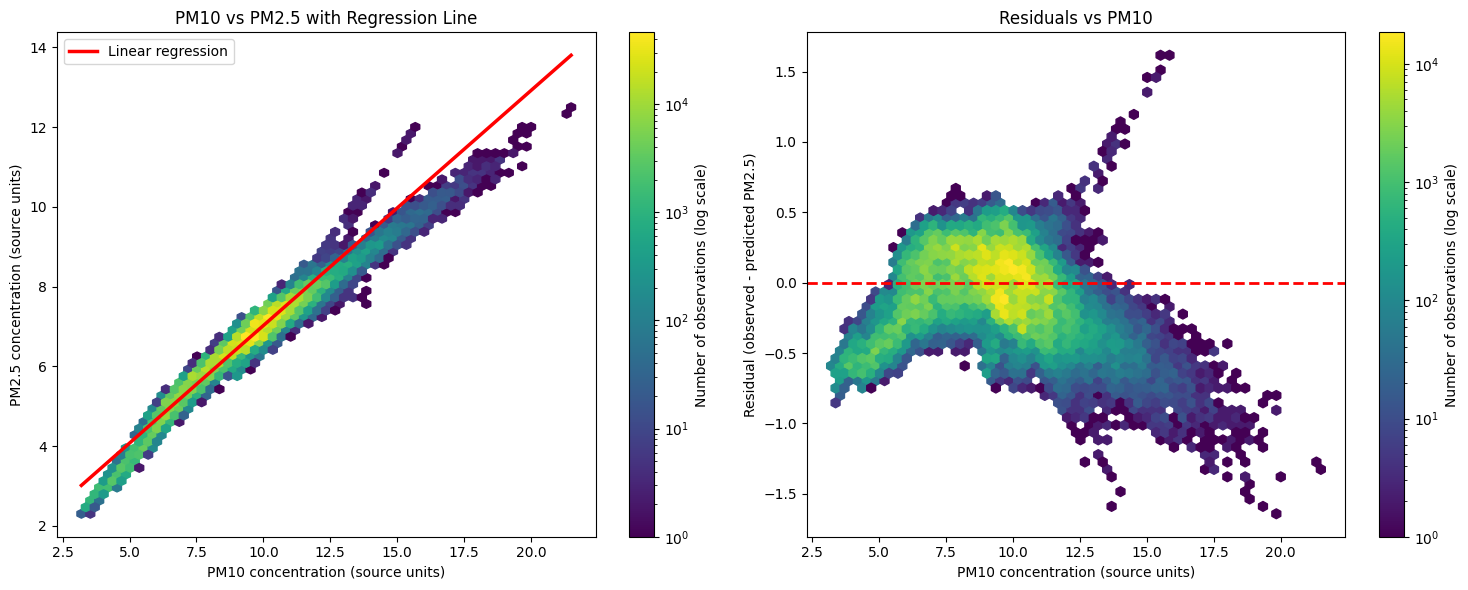

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Select the two pollutants
x = df["PM10"].to_numpy()
y = df["PM2.5"].to_numpy()

# Fit the linear regression model
X = x.reshape(-1, 1)
model = LinearRegression()
model.fit(X, y)

# Predicted PM2.5 values and residuals
y_pred = model.predict(X)
residuals = y - y_pred

# Calculate model diagnostics
r2 = r2_score(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))
mae = mean_absolute_error(y, y_pred)

print("Linear regression: PM2.5 predicted from PM10")
print(f"Intercept: {model.intercept_:.4f}")
print(f"Slope:     {model.coef_[0]:.4f}")
print(f"R-squared: {r2:.4f}")
print(f"RMSE:      {rmse:.4f}")
print(f"MAE:       {mae:.4f}")

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Hexbin plot with regression line
hb = axes[0].hexbin(
    x, y,
    gridsize=55,
    bins="log",
    mincnt=1,
    cmap="viridis"
)

x_line = np.linspace(x.min(), x.max(), 300)
y_line = model.predict(x_line.reshape(-1, 1))

axes[0].plot(
    x_line, y_line,
    color="red",
    linewidth=2.5,
    label="Linear regression"
)

axes[0].set_title("PM10 vs PM2.5 with Regression Line")
axes[0].set_xlabel("PM10 concentration (source units)")
axes[0].set_ylabel("PM2.5 concentration (source units)")
axes[0].legend()

cbar = fig.colorbar(hb, ax=axes[0])
cbar.set_label("Number of observations (log scale)")

# Plot 2: Residuals against PM10
hb2 = axes[1].hexbin(
    x, residuals,
    gridsize=55,
    bins="log",
    mincnt=1,
    cmap="viridis"
)

axes[1].axhline(0, color="red", linestyle="--", linewidth=2)
axes[1].set_title("Residuals vs PM10")
axes[1].set_xlabel("PM10 concentration (source units)")
axes[1].set_ylabel("Residual (observed - predicted PM2.5)")

cbar2 = fig.colorbar(hb2, ax=axes[1])
cbar2.set_label("Number of observations (log scale)")

plt.tight_layout()
plt.show()

**Mathematical inputs:**
A **residual** is the difference between what your model predicted (	ŷ) and what actually happened (y):
\{Residual}=y-\^y

If residuals are **systematic**, they show a clear visual shape or rule—such as a U-shape (curve), a wave, a funnel shape (heteroscedasticity), or a steady climb. This means the model is consistently over- or under-predicting in a specific way.

The ideal plot would look like a formless, chaotic cloud of points scattered evenly above and below the zero line.

# Results of the Linear Regression

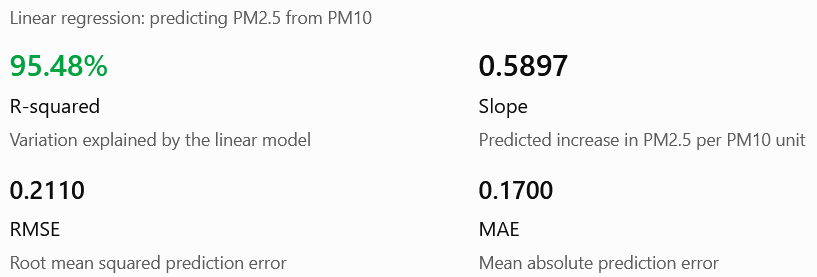

The fitted regression equation looks like
\[
\widehat{\mathrm{PM2.5}}
=1.1258+0.5897\,\mathrm{PM10}.
\] (idk how to make math stuff!)

This means that, according to the fitted model, a one-unit increase in PM10 corresponds to an average predicted increase of approximately 0.59 units in PM2.5.

The \(R^2\) value of 0.9548 means that the linear model accounts for about 95.48% of the observed variation in PM2.5 in this dataset. That is a very high proportion.

However, a high \(R^2\) alone does not establish that the model is appropriate across the full range of PM10 values.

**Summary**: the pollutants have a very strong association, but a straight line may not be the best functional description of that association.

**Residual plot**: the residual plot is systematic, it suggests that a straight line does not fully capture the relationship between PM10 and PM2.5.
Many residuals are positive. The linear model tends to underestimate PM2.5 in this region but a bit positive and slight underestimation is better than overestimating (region 5-13).

The residuals tend to become negative, particularly above approximately 13. The linear model tends to overestimate PM2.5 in this region.

**Conclusion**: The residuals are not randomly scattered around zero. Their changing pattern suggests that the relationship may be curved rather than perfectly linear.

**Next step**: compare linear and quadratic regression

# Compare linear and quadratic regression

Let's fit a quadratic model:
\[
\^y=b_0+b_1x+b_2x^2.
\]

This model can capture a curved relationship while remaining relatively simple to interpret. We should compare it with the linear model using the same observations and examine whether its residuals look less systematic.

Linear model: {'R-squared': 0.9548124960918104, 'RMSE': np.float64(0.21102970939576007), 'MAE': 0.16997967713907453}
Quadratic model: {'R-squared': 0.9680487610648931, 'RMSE': np.float64(0.17745092855983086), 'MAE': 0.1451020360413015}

Quadratic model equation:
PM2.5 = -0.7660 + (1.0447 * PM10) + (-0.0262 * PM10^2)


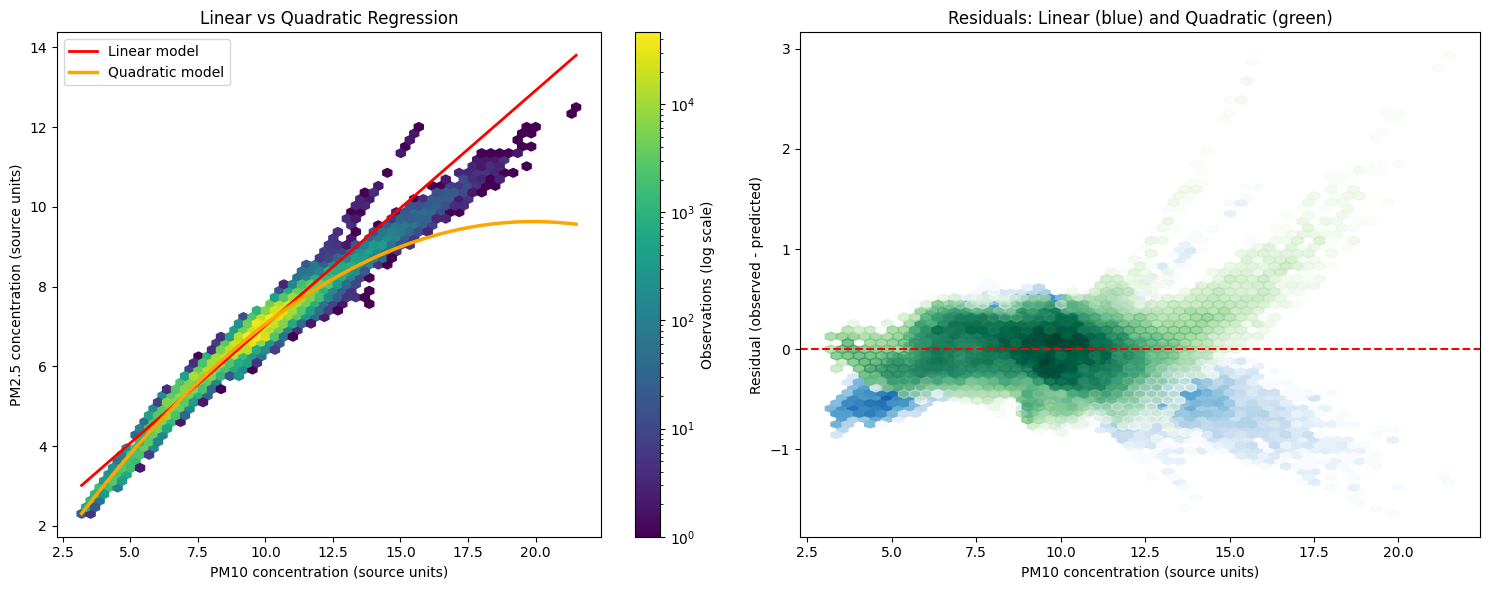

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Use the same data and observation order as before
x = df["PM10"].to_numpy()
y = df["PM2.5"].to_numpy()

# Fit linear model
X_linear = x.reshape(-1, 1)
linear_model = LinearRegression()
linear_model.fit(X_linear, y)
pred_linear = linear_model.predict(X_linear)

# Fit quadratic model
X_quad = np.column_stack([x, x**2])
quad_model = LinearRegression()
quad_model.fit(X_quad, y)
pred_quad = quad_model.predict(X_quad)

# Calculate residuals
resid_linear = y - pred_linear
resid_quad = y - pred_quad

# Compare model metrics
def model_metrics(observed, predicted):
    return {
        "R-squared": r2_score(observed, predicted),
        "RMSE": np.sqrt(mean_squared_error(observed, predicted)),
        "MAE": mean_absolute_error(observed, predicted)
    }

print("Linear model:", model_metrics(y, pred_linear))
print("Quadratic model:", model_metrics(y, pred_quad))

print("\nQuadratic model equation:")
print(f"PM2.5 = {quad_model.intercept_:.4f}"
      f" + ({quad_model.coef_[0]:.4f} * PM10)"
      f" + ({quad_model.coef_[1]:.4f} * PM10^2)")

# Create smooth fitted curves
x_grid = np.linspace(x.min(), x.max(), 400)
pred_linear_grid = linear_model.predict(x_grid.reshape(-1, 1))
pred_quad_grid = quad_model.predict(
    np.column_stack([x_grid, x_grid**2])
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot observed data and both fitted models
hb = axes[0].hexbin(
    x, y, gridsize=55, bins="log",
    mincnt=1, cmap="viridis"
)
axes[0].plot(
    x_grid, pred_linear_grid,
    color="red", linewidth=2,
    label="Linear model"
)
axes[0].plot(
    x_grid, pred_quad_grid,
    color="orange", linewidth=2.5,
    label="Quadratic model"
)
axes[0].set_title("Linear vs Quadratic Regression")
axes[0].set_xlabel("PM10 concentration (source units)")
axes[0].set_ylabel("PM2.5 concentration (source units)")
axes[0].legend()
fig.colorbar(hb, ax=axes[0], label="Observations (log scale)")

# Compare residual plots
axes[1].hexbin(
    x, resid_linear, gridsize=55, bins="log",
    mincnt=1, cmap="Blues"
)
axes[1].hexbin(
    x, resid_quad, gridsize=55, bins="log",
    mincnt=1, cmap="Greens", alpha=0.65
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuals: Linear (blue) and Quadratic (green)")
axes[1].set_xlabel("PM10 concentration (source units)")
axes[1].set_ylabel("Residual (observed - predicted)")

plt.tight_layout()
plt.show()

**Result**:
- The quadratic model explains approximately 96.80% of the variation in PM2.5, compared with 95.48% for the linear model.
- Its RMSE is approximately 15.9% lower.
- Its MAE is approximately 14.6% lower.
Both error measures indicate that the quadratic model predicts PM2.5 more accurately on the data used to fit it.

**Conclusion**: A quadratic model provides a better fit to your observed data.

**Residual plot**:
- Linear model (blue): The residuals show a systematic pattern, particularly at higher PM10 concentrations. This indicates that the straight line misses some of the curvature.
- Quadratic model (green): The central residual pattern is more balanced around zero. The strong systematic pattern is reduced.

However, the quadratic residuals still show some structure and a changing spread. In particular, there are positive residuals at higher PM10 values.

**Conclusion**: the quadratic regression provides a better description of the observed PM10–PM2.5 relationship than the linear regression.

**Correct workflow**:

Complete dataset -> Training data 80% (to fit and compare models) & Test data 20% (to do the final independent evaluation)

Training phase
- Fit linear regression.
- Fit quadratic regression.
- Compare residuals and training performance.
- Select the preferred model.

Testing phase
- Predict PM2.5 using the test data.
- Calculate R², RMSE and MAE.
- Evaluate the final model's performance on unseen observations.

# Let's create the split

In [16]:
from sklearn.model_selection import train_test_split

# Define explanatory and response variables
X = df[["PM10"]]
y = df["PM2.5"]

# Split into training and test data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))

Training observations: 838860
Test observations: 209715


# Fitting the linear model using the training data only:

In [22]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_train_pred = linear_model.predict(X_train)
linear_train_residuals = y_train - linear_train_pred

print("Linear regression equation:")
print(
    f"PM2.5 = {linear_model.intercept_:.4f} "
    f"+ {linear_model.coef_[0]:.4f} * PM10"
)

Linear regression equation:
PM2.5 = 1.1269 + 0.5896 * PM10


# Fitting the quadratic model using the training data only:

In [23]:
from sklearn.pipeline import make_pipeline

quadratic_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

quadratic_model.fit(X_train, y_train)

quadratic_train_pred = quadratic_model.predict(X_train)
quadratic_train_residuals = y_train - quadratic_train_pred

# Extract the fitted coefficients
poly_regression = quadratic_model.named_steps["linearregression"]

print("Quadratic regression equation:")
print(
    f"PM2.5 = {poly_regression.intercept_:.4f} "
    f"+ {poly_regression.coef_[0]:.4f} * PM10 "
    f"+ {poly_regression.coef_[1]:.4f} * PM10²"
)

Quadratic regression equation:
PM2.5 = -0.7695 + 1.0457 * PM10 + -0.0263 * PM10²


# Comparing both models using the train data:

In [24]:
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

training_results = pd.DataFrame({
    "Linear model": [
        r2_score(y_train, linear_train_pred),
        np.sqrt(mean_squared_error(y_train, linear_train_pred)),
        mean_absolute_error(y_train, linear_train_pred)
    ],
    "Quadratic model": [
        r2_score(y_train, quadratic_train_pred),
        np.sqrt(mean_squared_error(y_train, quadratic_train_pred)),
        mean_absolute_error(y_train, quadratic_train_pred)
    ]
}, index=["R-squared", "RMSE", "MAE"])

display(training_results.round(5))

,Linear model,Quadratic model
R-squared,0.95478,0.96802
RMSE,0.21102,0.17744
MAE,0.17001,0.14513


# Evaluating both models using the test data:

In [25]:
# Predictions on unseen test data
linear_test_pred = linear_model.predict(X_test)
quadratic_test_pred = quadratic_model.predict(X_test)

test_results = pd.DataFrame({
    "Linear model": [
        r2_score(y_test, linear_test_pred),
        np.sqrt(mean_squared_error(y_test, linear_test_pred)),
        mean_absolute_error(y_test, linear_test_pred)
    ],
    "Quadratic model": [
        r2_score(y_test, quadratic_test_pred),
        np.sqrt(mean_squared_error(y_test, quadratic_test_pred)),
        mean_absolute_error(y_test, quadratic_test_pred)
    ]
}, index=["R-squared", "RMSE", "MAE"])

display(test_results.round(5))

,Linear model,Quadratic model
R-squared,0.95496,0.96815
RMSE,0.21108,0.17750
MAE,0.16976,0.14493


# Summary
The linear regression model achieved an R² of 0.95496, an RMSE of 0.21108 and an MAE of 0.16976. The quadratic regression model performed better across all three evaluation metrics, achieving an R² of 0.96815, an RMSE of 0.17750 and an MAE of 0.14493.

The quadratic model therefore accounted for approximately 96.82% of the variation in PM2.5 concentrations in the test dataset, compared with 95.50% for the linear model. Furthermore, its RMSE was approximately 15.9% lower and its MAE approximately 14.6% lower than those of the linear model.

The consistent improvement across all three metrics indicates that the quadratic model provides a better description of the observed relationship between PM10 and PM2.5 and achieves more accurate predictions on the test data.

**Conclusion**: The quadratic model performs better

# Boosted trees

The main question is whether boosted trees can predict PM2.5 concentrations from PM10 measurements more accurately than the quadratic model.

We'll use the same three evaluation metrics:
- R²: Higher is better. Measures how much variation the model explains.
- RMSE: Lower is better. Penalises larger prediction errors.
- MAE: Lower is better. Measures the average absolute prediction error.

**Describing the parameters**:
- max_iter=200: Builds up to 200 boosting iterations (trees).
- learning_rate=0.1: Controls how much each iteration contributes to the model.
- max_leaf_nodes=15: Limits the complexity of each tree.
- random_state=42: Makes the results reproducible.

These are reasonable starting settings, not necessarily the optimal ones.

In [26]:
#we already created X_train, X_test, y_train, and y_test
from sklearn.ensemble import HistGradientBoostingRegressor

# Create the boosted tree model
boosted_model = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.1,
    max_leaf_nodes=15,
    random_state=42
)

# Train the model
boosted_model.fit(X_train, y_train)

# Make predictions on the test dataset
boosted_test_pred = boosted_model.predict(X_test)

# Evaluate the boosted tree model (calculate metrics)

In [27]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Calculate evaluation metrics
boosted_r2 = r2_score(y_test, boosted_test_pred)
boosted_rmse = np.sqrt(mean_squared_error(y_test, boosted_test_pred))
boosted_mae = mean_absolute_error(y_test, boosted_test_pred)

print("Boosted Tree Model Performance")
print("--------------------------------")
print(f"R²:   {boosted_r2:.5f}")
print(f"RMSE: {boosted_rmse:.5f}")
print(f"MAE:  {boosted_mae:.5f}")

Boosted Tree Model Performance
--------------------------------
R²:   0.97088
RMSE: 0.16972
MAE:  0.13839


# Compare all three models

We put the results into a table:

In [28]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Quadratic Regression",
        "Boosted Trees"
    ],
    "R²": [
        r2_score(y_test, linear_test_pred),
        r2_score(y_test, quadratic_test_pred),
        boosted_r2
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, linear_test_pred)),
        np.sqrt(mean_squared_error(y_test, quadratic_test_pred)),
        boosted_rmse
    ],
    "MAE": [
        mean_absolute_error(y_test, linear_test_pred),
        mean_absolute_error(y_test, quadratic_test_pred),
        boosted_mae
    ]
})

print(comparison.round(5))

                  Model       R²     RMSE      MAE
0     Linear Regression  0.95496  0.21108  0.16976
1  Quadratic Regression  0.96815  0.17750  0.14493
2         Boosted Trees  0.97088  0.16972  0.13839


**Summary**: The boosted tree model performs best across all three evaluation metrics.

The quadratic regression assumes that the relationship follows a particular mathematical form. Boosted trees, on the other hand, can capture more flexible non-linear relationships.

# Neural Network

**Standardisation**

For the neural network we only standardise PM10, because PM10 is the input variable.

PM2.5 is the target variable that the network is trying to predict.

It is possible to standardise the target variable as well, but it is not necessary here.

# Data Preparation for NN

In [31]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit the scaler using training data only
X_train_scaled = scaler.fit_transform(X_train)

# Transform the test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Original PM10 values:")
print(X_train.head())

print("\nStandardised PM10 values:")
print(X_train_scaled[:5])

Original PM10 values:
        PM10
408561   9.2
70143    9.4
708782   9.4
572694   9.4
774181  10.8

Standardised PM10 values:
[[-0.0435247 ]
 [ 0.07809272]
 [ 0.07809272]
 [ 0.07809272]
 [ 0.92941466]]


# Building the neural network

We build a Multilayer Neural Net (Multilayer Perceptron/MLP)
Input: PM10 concentration

Output: Predicted PM2.5 concentration

Between them: Two hidden layers that learn patterns in the relationship between PM10 and PM2.5.

- First hidden layer: 64 neurons

- Second hidden layer: 32 neurons

- Activation function: ReLU

- Optimiser: Adam

**Description of maths**:
**ReLu** = Rectified Linear Unit.

It is an activation function. Its purpose is to introduce non-linearity into the neural network.

Without non-linear activation functions, the neural net would behave like a linear function.

ReLU is mathematically defined as:
\
f(x)=max(0,x)

**ReLu is simple to use and so popular.**

**Why not a quadratic activation function?**

Stacking quadratic activation functions can produce polynomials of increasingly high degrees, which may make the network unnecessarily complicated and difficult to train.

We might try a quadratic activation funtion in a later module.

In [33]:
from sklearn.neural_network import MLPRegressor

# Create the neural network
neural_model = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=300,
    early_stopping=True,
    validation_fraction=0.1,
    n_iter_no_change=15,
    random_state=42 #for reproducability
)

# Train the neural network
neural_model.fit(X_train_scaled, y_train)

# Make predictions on the test dataset
neural_test_pred = neural_model.predict(X_test_scaled)

# Evaluate the neural net model (calculate metrics)

In [34]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Calculate evaluation metrics
neural_r2 = r2_score(y_test, neural_test_pred)

neural_rmse = np.sqrt(
    mean_squared_error(y_test, neural_test_pred)
)

neural_mae = mean_absolute_error(
    y_test, neural_test_pred
)

print("Neural Network Performance")
print("---------------------------")
print(f"R²:   {neural_r2:.5f}")
print(f"RMSE: {neural_rmse:.5f}")
print(f"MAE:  {neural_mae:.5f}")

Neural Network Performance
---------------------------
R²:   0.97082
RMSE: 0.16989
MAE:  0.13890


# Compare all four models
In a table:

In [35]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Quadratic Regression",
        "Boosted Trees",
        "Neural Network"
    ],
    "R²": [
        r2_score(y_test, linear_test_pred),
        r2_score(y_test, quadratic_test_pred),
        r2_score(y_test, boosted_test_pred),
        neural_r2
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, linear_test_pred)),
        np.sqrt(mean_squared_error(y_test, quadratic_test_pred)),
        np.sqrt(mean_squared_error(y_test, boosted_test_pred)),
        neural_rmse
    ],
    "MAE": [
        mean_absolute_error(y_test, linear_test_pred),
        mean_absolute_error(y_test, quadratic_test_pred),
        mean_absolute_error(y_test, boosted_test_pred),
        neural_mae
    ]
})

print(comparison.round(5))

                  Model       R²     RMSE      MAE
0     Linear Regression  0.95496  0.21108  0.16976
1  Quadratic Regression  0.96815  0.17750  0.14493
2         Boosted Trees  0.97088  0.16972  0.13839
3        Neural Network  0.97082  0.16989  0.13890


# Visualise the comparison

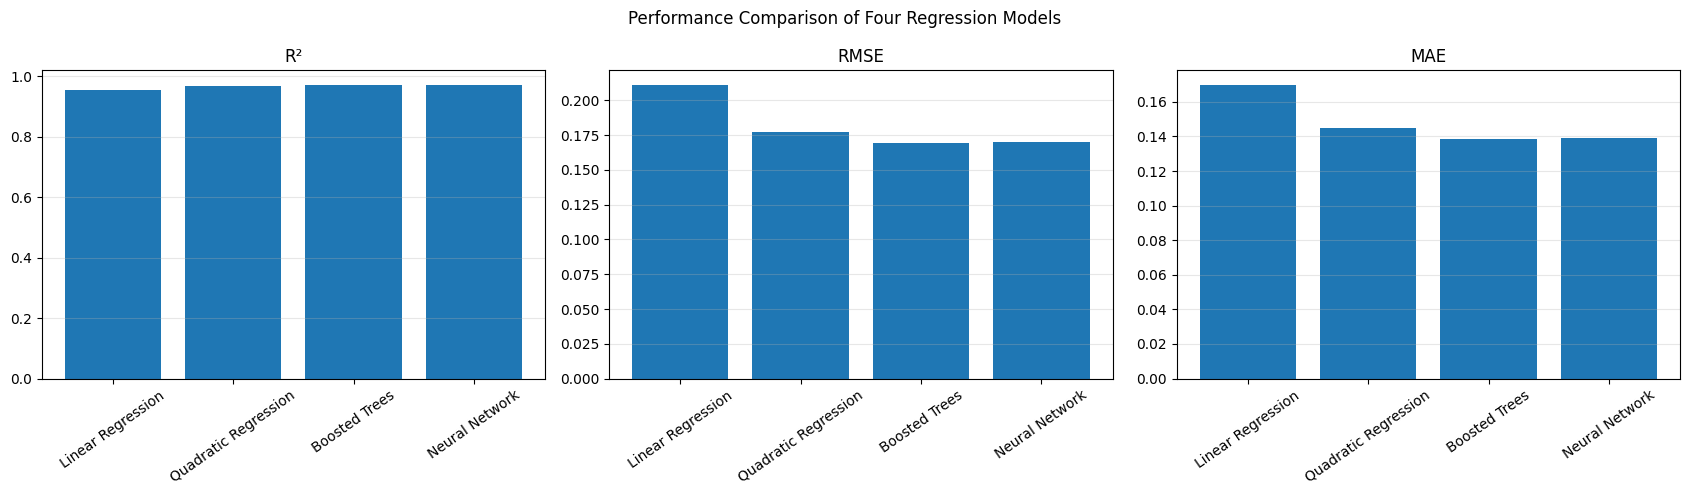

In [36]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

metrics = ["R²", "RMSE", "MAE"]

for ax, metric in zip(axes, metrics):
    ax.bar(comparison["Model"], comparison[metric])
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Performance Comparison of Four Regression Models")
plt.tight_layout()
plt.show()

# Final Comparison Conclusion

The boosted tree and neural network models achieve better results than both linear and quadratic regression.

This suggests that more flexible modelling approaches can capture additional patterns in the relationship between PM10 and PM2.5.

But the quadratic model already performed very well.

# Stuff I might have to do later

For the final project I would need to add a Swiss map to the dataset visialisation, geographic pollution map:
Plot Longitude and Latitude, using colour to represent the concentration of a pollutant.
- Answers: Where are pollution levels higher or lower?
- Best for: Discovering geographic hotspots and spatial patterns.
To identify the hotspots: rank grid cells by average pollutant concentration and examine the highest values.

Compare pollutants: create small-multiple maps and a correlation heatmap. A correlation heatmap would show the correlations between O3, PM10, PM2.5, SO2 and NOX.
- Answers: Which pollutants tend to increase or decrease together?
- Best for: Identifying relationships between pollutants.

Refine the maps: add Swiss borders or canton boundaries once the coordinate reference system has been confirmed.

And also, I have to fomulate a nice and clear Fragestellung, which I can answer.
Then for the final project I could extend the prediction model to the other 3 pollutants. At the end I need to put the whole text in a grammar correction programme.
For design purposes I could transfer all my text into LaTex to make it look nice.

In M3 we noticed that we coud try a quadratic activation funtion for the neural network

What I could be looking at next:

Before selecting my final model, I could do two additional analyses.

A. Residual comparison

Compare the residuals of the boosted tree and neural network models.

We want to investigate:
- Whether the residuals are randomly distributed around zero.
- Whether either model systematically overestimates or underestimates PM2.5.
- Whether prediction errors increase at higher PM10 concentrations.
- Whether one model captures patterns that the other misses.

B. Check the reliability of the test results

The differences are extremely small. It would therefore be useful to check whether they are stable across different data splits or cross-validation folds.

Also, because my data contains geographical coordinates, it might be good to consider whether measurements from the same monitoring stations appear in both training and test datasets. A spatial or station-based validation would be important if the objective is to predict pollution at new locations.